In [8]:
# Cell 1
import os
import glob
import ast
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


device = torch.device("cpu")
torch.set_num_threads(os.cpu_count())

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("CPU threads:", torch.get_num_threads())

PyTorch version: 2.5.1
Device: cpu
CPU threads: 22


In [9]:
# Cell 2
hits = glob.glob("../data/**/ptbxl_database.csv", recursive=True)
assert len(hits) > 0, "Could not find ptbxl_database.csv inside ../data"

DATA_DIR = os.path.dirname(hits[0])

os.makedirs("../results", exist_ok=True)
os.makedirs("../models", exist_ok=True)

Y = pd.read_csv(f"{DATA_DIR}/ptbxl_database.csv", index_col="ecg_id")
Y["scp_codes"] = Y["scp_codes"].apply(ast.literal_eval)

scp = pd.read_csv(f"{DATA_DIR}/scp_statements.csv", index_col=0)
scp = scp[scp.diagnostic == 1]

print("Data folder:", DATA_DIR)
print("Total recordings:", len(Y))
print("Diagnostic statements:", len(scp))

Data folder: ../data\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Total recordings: 21799
Diagnostic statements: 44


In [ ]:
# Cell 3
def get_diagnostic_classes(codes):
    return {
        scp.loc[code].diagnostic_class
        for code in codes
        if code in scp.index
    }


def make_label(classes):
    has_norm = "NORM" in classes
    has_mi = "MI" in classes

    if has_norm and not has_mi:
        return 0
    if has_mi and not has_norm:
        return 1

    return -1


Y["diagnostic_classes"] = Y["scp_codes"].apply(get_diagnostic_classes)
Y["label"] = Y["diagnostic_classes"].apply(make_label)

Y_binary = Y[Y["label"] >= 0].copy()

print("NORM (0):", (Y_binary["label"] == 0).sum())
print("MI (1):", (Y_binary["label"] == 1).sum())
print("Total used:", len(Y_binary))
print()
print(Y_binary.groupby("strat_fold")["label"].agg(["count", "mean"]))

NORM (0): 9513
MI (1): 5468
Total used: 14981

            count      mean
strat_fold                 
1            1489  0.368704
2            1505  0.357475
3            1519  0.347597
4            1478  0.372801
5            1502  0.374834
6            1490  0.376510
7            1520  0.361842
8            1470  0.365986
9            1495  0.361204
10           1513  0.363516


In [11]:
# Cell 4
CACHE_PATH = "../data/ptbxl_norm_mi_100hz.npz"

if os.path.exists(CACHE_PATH):
    cached = np.load(CACHE_PATH)
    X = cached["X"]
    y = cached["y"]
    folds = cached["folds"]
    print("Loaded signals from cache")
else:
    signals = []

    for i, filename in enumerate(Y_binary["filename_lr"]):
        signal, meta = wfdb.rdsamp(f"{DATA_DIR}/{filename}")
        signals.append(signal)

        if (i + 1) % 2000 == 0:
            print(f"Loaded {i + 1}/{len(Y_binary)}")

    X = np.stack(signals).astype(np.float32)
    y = Y_binary["label"].values
    folds = Y_binary["strat_fold"].values

    np.savez_compressed(CACHE_PATH, X=X, y=y, folds=folds)
    print("Saved cache to", CACHE_PATH)

print("Signal array shape:", X.shape)
print("Label array shape:", y.shape)

Loaded 2000/14981
Loaded 4000/14981
Loaded 6000/14981
Loaded 8000/14981
Loaded 10000/14981
Loaded 12000/14981
Loaded 14000/14981
Saved cache to ../data/ptbxl_norm_mi_100hz.npz
Signal array shape: (14981, 1000, 12)
Label array shape: (14981,)


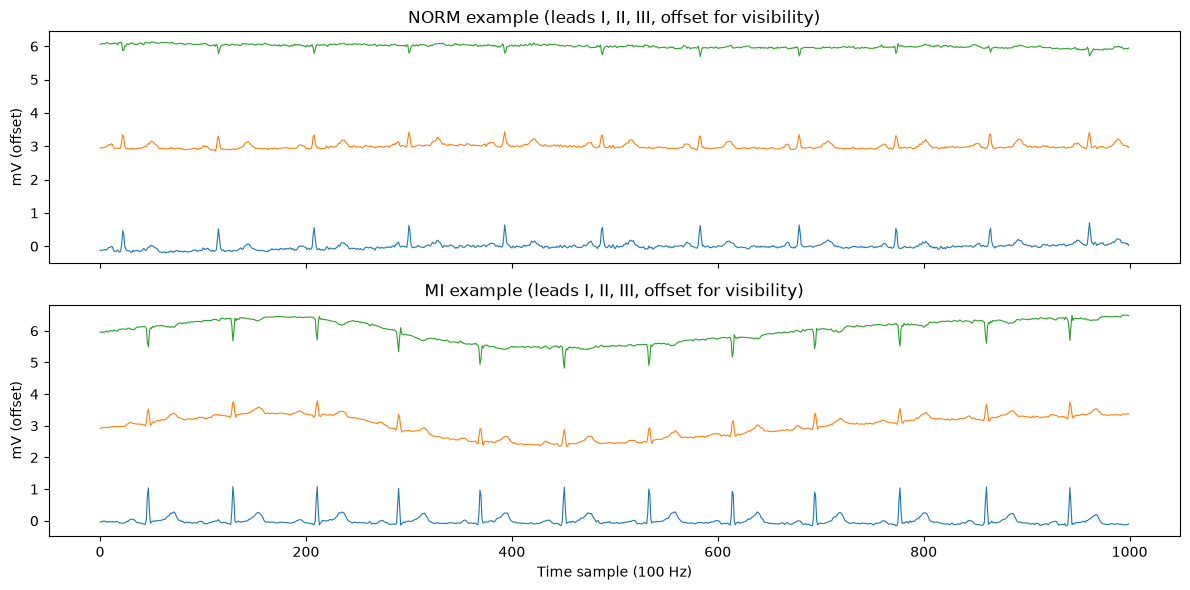

In [12]:
# Cell 5
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, class_id, class_name in zip(axes, [0, 1], ["NORM", "MI"]):
    index = np.where(y == class_id)[0][0]

    for lead in range(3):
        ax.plot(X[index, :, lead] + lead * 3, linewidth=0.8)

    ax.set_title(f"{class_name} example (leads I, II, III, offset for visibility)")
    ax.set_ylabel("mV (offset)")

axes[1].set_xlabel("Time sample (100 Hz)")

plt.tight_layout()
plt.savefig("../results/example_ecgs.png", dpi=150)
plt.show()

In [13]:
# Cell 6
X_norm = X / (np.abs(X).max(axis=1, keepdims=True) + 1e-8)

X_norm = X_norm.transpose(0, 2, 1)[:, None, :, :].astype(np.float32)

train_mask = folds <= 8
val_mask = folds == 9
test_mask = folds == 10

BATCH_SIZE = 64


def make_loader(mask, shuffle):
    dataset = TensorDataset(
        torch.from_numpy(X_norm[mask]),
        torch.from_numpy(y[mask]).long()
    )
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)


train_loader = make_loader(train_mask, shuffle=True)
val_loader = make_loader(val_mask, shuffle=False)
test_loader = make_loader(test_mask, shuffle=False)

print("Training ECGs:", train_mask.sum(), "| MI fraction:", y[train_mask].mean().round(3))
print("Validation ECGs:", val_mask.sum(), "| MI fraction:", y[val_mask].mean().round(3))
print("Test ECGs:", test_mask.sum(), "| MI fraction:", y[test_mask].mean().round(3))

ecgs, labels = next(iter(train_loader))

print("ECG batch shape:", ecgs.shape)
print("Label batch shape:", labels.shape)
print("Value range:", ecgs.min().item(), "to", ecgs.max().item())

Training ECGs: 11973 | MI fraction: 0.366
Validation ECGs: 1495 | MI fraction: 0.361
Test ECGs: 1513 | MI fraction: 0.364
ECG batch shape: torch.Size([64, 1, 12, 1000])
Label batch shape: torch.Size([64])
Value range: -1.0 to 1.0


In [ ]:
# Cell 7
class TemporalResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=(1, 3),
            stride=(1, stride),
            padding=(0, 1),
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=(1, 3),
            stride=1,
            padding=(0, 1),
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if in_channels != out_channels or stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=(1, 1),
                    stride=(1, stride),
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        out = self.relu(out)

        return out

In [ ]:
# Cell 8
CHANNELS = [64, 48, 32, 16]


def make_stage(in_channels, out_channels, stride):
    return nn.Sequential(
        TemporalResidualBlock(in_channels, out_channels, stride=stride),
        TemporalResidualBlock(out_channels, out_channels, stride=1)
    )


class ECGSmartNet(nn.Module):
    def __init__(self, num_classes=2, channels=CHANNELS):
        super().__init__()

        c1, c2, c3, c4 = channels

        self.stem = nn.Sequential(
            nn.Conv2d(
                1, c1,
                kernel_size=(1, 7),
                stride=(1, 2),
                padding=(0, 3),
                bias=False
            ),
            nn.BatchNorm2d(c1),
            nn.ReLU(inplace=True)
        )

        self.maxpool = nn.MaxPool2d(
            kernel_size=(1, 3),
            stride=(1, 2),
            padding=(0, 1)
        )

        self.stage1 = make_stage(c1, c1, stride=1)
        self.stage2 = make_stage(c1, c2, stride=2)
        self.stage3 = make_stage(c2, c3, stride=2)
        self.stage4 = make_stage(c3, c4, stride=2)

        self.spatial = nn.Sequential(
            nn.Conv2d(
                c4, c4,
                kernel_size=(12, 1),
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(c4),
            nn.ReLU(inplace=True)
        )

        self.avgpool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Linear(c4, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.maxpool(x)

        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)

        x = self.spatial(x)

        x = self.avgpool(x)
        x = torch.flatten(x, start_dim=1)

        x = self.classifier(x)

        return x

In [19]:
# Cell 9
model = ECGSmartNet(num_classes=2).to(device)

dummy_input = torch.randn(BATCH_SIZE, 1, 12, 1000, device=device)

with torch.no_grad():
    dummy_output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Model device:", next(model.parameters()).device)

Input shape: torch.Size([64, 1, 12, 1000])
Output shape: torch.Size([64, 2])
Total parameters: 107,074
Trainable parameters: 107,074
Model device: cpu


In [20]:
# Cell 10
model.eval()

with torch.no_grad():
    x = torch.randn(1, 1, 12, 1000, device=device)

    print("Input:   ", x.shape)

    x = model.stem(x)
    print("Stem:    ", x.shape)

    x = model.maxpool(x)
    print("MaxPool: ", x.shape)

    x = model.stage1(x)
    print("Stage 1: ", x.shape)

    x = model.stage2(x)
    print("Stage 2: ", x.shape)

    x = model.stage3(x)
    print("Stage 3: ", x.shape)

    x = model.stage4(x)
    print("Stage 4: ", x.shape)

    x = model.spatial(x)
    print("Spatial: ", x.shape)

    x = model.avgpool(x)
    print("AvgPool: ", x.shape)

    x = torch.flatten(x, start_dim=1)
    print("Flatten: ", x.shape)

    x = model.classifier(x)
    print("Output:  ", x.shape)

Input:    torch.Size([1, 1, 12, 1000])
Stem:     torch.Size([1, 64, 12, 500])
MaxPool:  torch.Size([1, 64, 12, 250])
Stage 1:  torch.Size([1, 64, 12, 250])
Stage 2:  torch.Size([1, 48, 12, 125])
Stage 3:  torch.Size([1, 32, 12, 63])
Stage 4:  torch.Size([1, 16, 12, 32])
Spatial:  torch.Size([1, 16, 1, 32])
AvgPool:  torch.Size([1, 16, 1, 1])
Flatten:  torch.Size([1, 16])
Output:   torch.Size([1, 2])


In [21]:
# Cell 11
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
EPOCHS = 10
PATIENCE = 4

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Weight decay: 0.0001
Epochs: 10
Early stopping patience: 4


In [22]:
# Cell 12
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for ecgs, labels in loader:
        ecgs = ecgs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(ecgs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    average_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for ecgs, labels in loader:
            ecgs = ecgs.to(device)
            labels = labels.to(device)

            outputs = model(ecgs)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

    average_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy

In [23]:
# Cell 13
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

MODEL_PATH = "../models/ecg_smart_net_best.pt"

best_val_loss = float("inf")
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Time: {time.time() - epoch_start:.0f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), MODEL_PATH)
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping: validation loss stopped improving")
            break

elapsed_time = time.time() - start_time

print(f"\nTraining time: {elapsed_time:.1f} seconds")

Epoch [1/10] | Train Loss: 0.3261 | Train Acc: 87.81% | Val Loss: 0.2874 | Val Acc: 87.29% | Time: 83s
Epoch [2/10] | Train Loss: 0.2249 | Train Acc: 90.95% | Val Loss: 0.2846 | Val Acc: 88.63% | Time: 83s
Epoch [3/10] | Train Loss: 0.2027 | Train Acc: 91.91% | Val Loss: 0.2287 | Val Acc: 90.17% | Time: 81s
Epoch [4/10] | Train Loss: 0.1798 | Train Acc: 92.88% | Val Loss: 0.2241 | Val Acc: 90.64% | Time: 82s
Epoch [5/10] | Train Loss: 0.1777 | Train Acc: 92.98% | Val Loss: 0.1979 | Val Acc: 92.44% | Time: 84s
Epoch [6/10] | Train Loss: 0.1707 | Train Acc: 93.14% | Val Loss: 0.2324 | Val Acc: 90.30% | Time: 81s
Epoch [7/10] | Train Loss: 0.1748 | Train Acc: 93.05% | Val Loss: 0.2153 | Val Acc: 91.24% | Time: 84s
Epoch [8/10] | Train Loss: 0.1589 | Train Acc: 93.84% | Val Loss: 0.2105 | Val Acc: 91.10% | Time: 84s
Epoch [9/10] | Train Loss: 0.1560 | Train Acc: 93.59% | Val Loss: 0.2298 | Val Acc: 91.44% | Time: 83s
Early stopping: validation loss stopped improving

Training time: 745.0 s

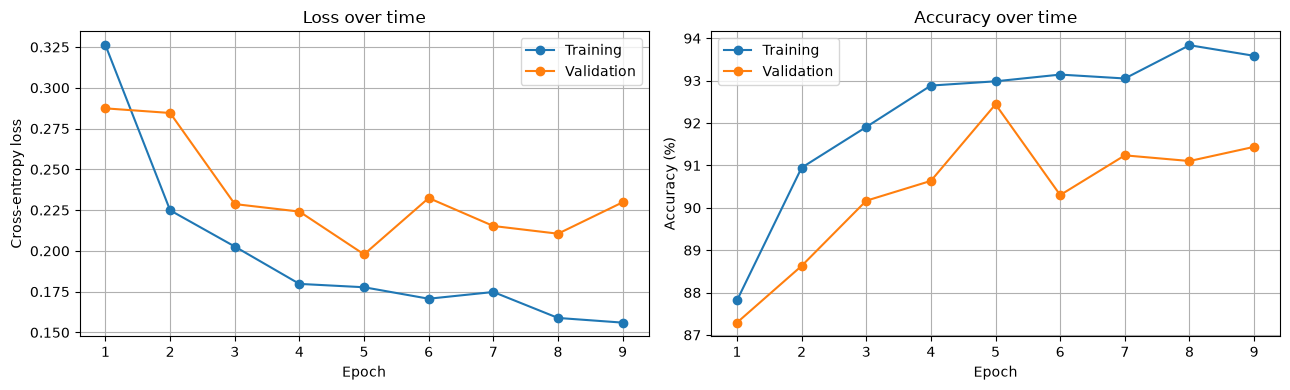

In [24]:
# Cell 14
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss over time")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy over time")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("../results/training_curves.png", dpi=150)
plt.show()